# 02 · Baseline models

**Goal:** set a reference point before trying stronger models. Three baselines
are compared on the **validation** split:

1. a trivial **"never fraud"** model, to show why accuracy is misleading here;
2. the simulator's **legacy rule** (`isFlaggedFraud`), used only as a comparison
   score, never as a feature;
3. a **logistic regression** with balanced class weights and standard scaling.

The **test split is not used in this notebook.** It is set aside right after the
split and only touched once, for the final model.

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

from src.data import load_data
from src.features import filter_relevant, default_boundaries, time_split, build_features
from src.models import make_logreg_baseline, SEED
from src.evaluate import evaluate_model, plot_pr_curve, plot_confusion_matrix, save_metrics
from src.plotting import set_style

np.random.seed(SEED)
set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Data, split and features

In [2]:
df = load_data(money_dtype="float64")
df = filter_relevant(df)
print()
train_end, val_end = default_boundaries(df["step"])
train, val, test = time_split(df, train_end, val_end)

# Set the test split aside: it is not used anywhere in this notebook.
n_test_rows = len(test)
del test, df

X_train, y_train = build_features(train), train["isFraud"].astype(int)
X_val, y_val = build_features(val), val["isFraud"].astype(int)
print(f"\nFeatures ({X_train.shape[1]}): {list(X_train.columns)}")

Before filter:  6,362,620 rows |  8,213 fraud | fraud rate 0.1291%
After filter:   2,770,409 rows |  8,213 fraud | fraud rate 0.2965%
Removed 3,592,211 rows (56.5%), 0 of them fraud.



train steps   1-520  2,653,729 rows |  5,781 fraud | fraud rate 0.2178%
val   steps 521-632     78,709 rows |  1,188 fraud | fraud rate 1.5094%
test  steps 633-743     37,971 rows |  1,244 fraud | fraud rate 3.2762%



Features (8): ['amount_log', 'errorBalanceOrig', 'errorBalanceDest', 'orig_emptied', 'dest_new_or_zero', 'hour', 'amount_to_balance_ratio', 'is_transfer']


The split is by time: training covers steps 1 to 520, validation 521 to 632. As
the EDA showed, legitimate volume collapses late in the simulation, so the
validation fraud rate is far higher than the training rate. **Every PR-AUC below
should be read against the validation base rate**, which is what a random model
would score.

Behaviour features are left out here: origin accounts almost never repeat in
PaySim, so they are nearly always 0.

## 2. Why accuracy is misleading: the "never fraud" model

In [3]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_scores = dummy.predict_proba(X_val)[:, 1]
dummy_metrics = evaluate_model(y_val, dummy_scores)

pd.DataFrame({
    "accuracy": [accuracy_score(y_val, dummy.predict(X_val))],
    "PR-AUC": [dummy_metrics["pr_auc"]],
    "recall": [dummy_metrics["recall"]],
    "frauds caught": [f"{dummy_metrics['tp']} of {dummy_metrics['n_fraud']:,}"],
}, index=["never fraud"])

,accuracy,PR-AUC,recall,frauds caught
never fraud,0.9849,0.0151,0.0000,"0 of 1,188"


**Takeaway:** a model that never predicts fraud is **98.49% accurate** on the
validation set and **catches none of its 1,188 frauds**. Its PR-AUC equals the
base rate (about 1.5%), which correctly says it has no skill. Accuracy is shown
here only to make this point; from now on models are compared on PR-AUC,
precision and recall.

## 3. Logistic regression

In [4]:
logreg = make_logreg_baseline()
t0 = time.time()
logreg.fit(X_train, y_train)   # the scaler is fitted on training rows only
print(f"Trained on {len(X_train):,} rows in {time.time() - t0:.0f}s")

val_scores = logreg.predict_proba(X_val)[:, 1]
train_scores = logreg.predict_proba(X_train)[:, 1]

coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=X_train.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).to_frame("coefficient (scaled features)")

Trained on 2,653,729 rows in 18s


,coefficient (scaled features)
errorBalanceOrig,-20.8548
amount_to_balance_ratio,16.7999
orig_emptied,2.8020
errorBalanceDest,1.4598
amount_log,0.5376
is_transfer,0.5102
hour,-0.4126
dest_new_or_zero,0.2312


Coefficients are on standardised features, so their sizes are roughly comparable.
A positive coefficient pushes the prediction towards fraud.

## 4. Validation results

In [5]:
THRESHOLD = 0.5
logreg_val = evaluate_model(y_val, val_scores, THRESHOLD)
logreg_train = evaluate_model(y_train, train_scores, THRESHOLD)
rule_val = evaluate_model(y_val, val["isFlaggedFraud"], THRESHOLD)

cols = ["pr_auc", "roc_auc", "precision", "recall", "f1", "tp", "fp", "fn"]
comparison = pd.DataFrame(
    {"never fraud": dummy_metrics, "legacy rule (isFlaggedFraud)": rule_val,
     "logistic regression": logreg_val}
).T[cols]
print(f"Validation: {logreg_val['n']:,} rows, {logreg_val['n_fraud']:,} fraud, "
      f"base rate {logreg_val['base_rate']:.4%}. Threshold = {THRESHOLD}")
comparison

Validation: 78,709 rows, 1,188 fraud, base rate 1.5094%. Threshold = 0.5


,pr_auc,roc_auc,precision,recall,f1,tp,fp,fn
never fraud,0.0151,0.5000,0.0000,0.0000,0.0000,0,0,1188
legacy rule (isFlaggedFraud),0.0176,0.5013,1.0000,0.0025,0.0050,3,0,1185
logistic regression,0.8786,0.9905,0.1794,0.9832,0.3035,1168,5341,20


In [6]:
print(f"Logistic regression PR-AUC  train: {logreg_train['pr_auc']:.4f} "
      f"(base rate {logreg_train['base_rate']:.4%})  |  "
      f"validation: {logreg_val['pr_auc']:.4f} (base rate {logreg_val['base_rate']:.4%})")

Logistic regression PR-AUC  train: 0.7297 (base rate 0.2178%)  |  validation: 0.8786 (base rate 1.5094%)


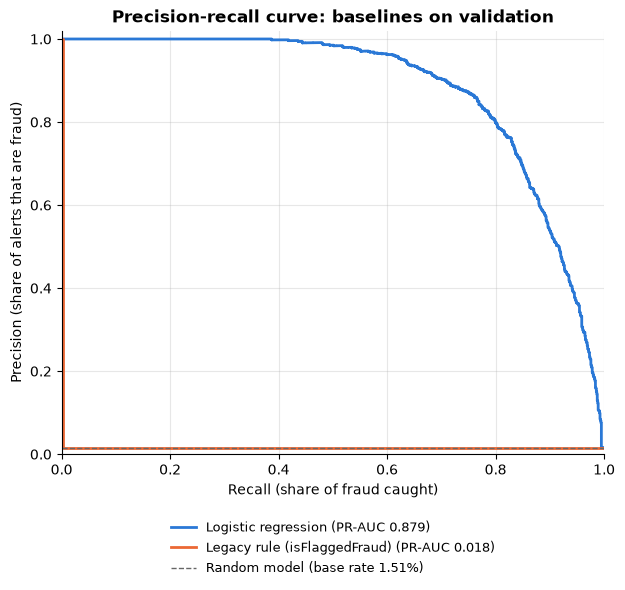

In [7]:
fig = plot_pr_curve(
    {"Logistic regression": (y_val, val_scores),
     "Legacy rule (isFlaggedFraud)": (y_val, val["isFlaggedFraud"])},
    title="Precision-recall curve: baselines on validation",
)
plt.show()

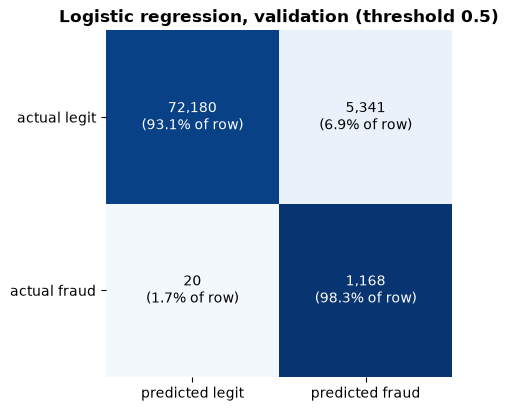

In [8]:
fig = plot_confusion_matrix(
    logreg_val["confusion_matrix"],
    title=f"Logistic regression, validation (threshold {THRESHOLD})",
    name="baseline_confusion_matrix",
)
plt.show()

## 5. Save metrics

In [9]:
metrics = {
    "split": {
        "train_steps": [int(train["step"].min()), int(train_end)],
        "val_steps": [int(train_end) + 1, int(val_end)],
        "train_rows": int(len(train)),
        "val_rows": int(len(val)),
        "test_rows_not_used": int(n_test_rows),
    },
    "features": list(X_train.columns),
    "threshold": THRESHOLD,
    "validation": {
        "never_fraud": dummy_metrics,
        "legacy_rule": rule_val,
        "logistic_regression": logreg_val,
    },
    "train": {"logistic_regression": logreg_train},
}
path = save_metrics(metrics, ROOT / "reports" / "baseline_metrics.json")
print(f"Saved {path.relative_to(ROOT)}")

Saved reports\baseline_metrics.json


## Summary

**What the baseline gets right**

- **It ranks fraud very well.** Validation PR-AUC is **0.879** against a base rate
  of 1.51%, about 58 times better than random (ROC-AUC 0.991). The PR curve stays
  at about 100% precision up to roughly 38% recall and is still about 80% precise
  at 80% recall, so the highest-scored transactions are almost all fraud.
- **It beats the legacy rule by a wide margin.** `isFlaggedFraud` caught 3 of
  1,188 validation frauds (PR-AUC 0.018, barely above random).
- **It relies on the signals the EDA found.** The largest coefficients are on
  `errorBalanceOrig` and `amount_to_balance_ratio`, and `orig_emptied` pushes
  towards fraud. The negative sign on `errorBalanceOrig` makes sense: legitimate
  transfers from accounts already at zero leave a large origin balance error,
  while fraud drains a funded account exactly, leaving an error near 0.
- **No sign of overfitting.** Training PR-AUC (0.730) is *lower* than validation
  (0.879). The gap comes from the base rates (0.22% vs 1.51%), not from
  memorisation: PR-AUC is not comparable across datasets with different base rates.

**What it gets wrong**

- **Threshold 0.5 is arbitrary and expensive.** Balanced class weights push scores
  up, so at 0.5 the model catches 98.3% of fraud (1,168) but raises **5,341 false
  alarms**: precision 17.9%, about 4.6 false alerts per fraud caught, and 8.3% of
  all validation transactions flagged. On training data the same threshold gives
  only 3.4% precision. The threshold has to be chosen from the cost of a missed
  fraud vs the cost of reviewing an alert; that is the next step.
- **A linear model struggles with heavy-tailed features.** Its two largest
  coefficients (-20.9 and +16.8) sit on features with extreme ranges: the
  amount-to-balance ratio can reach millions when the origin balance is near 0.
  Scaling does not tame heavy tails, so the model depends on a few extreme values.
  Log-transforming or clipping, or a tree model, would handle this better.
- **It cannot use non-linear patterns.** `hour` gets a single coefficient (-0.41),
  but the fraud rate peaks between hours 3 and 6 and is low otherwise; a straight
  line cannot represent that bump. The same goes for interactions such as
  "TRANSFER and drained account". A gradient-boosted tree model (XGBoost) is the
  natural next candidate.
- **Validation precision is flattering.** The validation period has 15 times the
  training fraud rate. At a realistic base rate of 0.2 to 0.3%, the same recall
  and false-alarm rate would give much lower precision, so precision must always
  be read alongside the base rate it was measured at.